In [1]:
!nvidia-smi

Sat Aug  8 19:16:04 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   48C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
%load_ext cudf.pandas

In [3]:
%config InlineBackend.figure_format = 'retina'
%matplotlib inline

In [41]:
# Connect with Google Drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [42]:
# Data manipulation
import numpy as np
import pandas as pd

# Graphs
import seaborn as sns
import matplotlib.pyplot as plt

# warnings
import warnings

In [43]:
warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
sns.set_style("ticks")
odx = pd.IndexSlice
pd.set_option('display.max_columns', 100)
pd.set_option('display.float_format', lambda x: '%.2f' % x)

In [44]:
def read_url(link):
    """ Creates a pandas DataFrame from data online
    - Parameters:
        - link: link to the zipped data
    - Returns:
    """
    import io
    import requests
    import pandas as pd

    # Define URL and extract information
    response = requests.get(link)
    content = response.content
    # Convert into a Pandas DataFrame
    df = pd.read_csv(io.BytesIO(content), sep=',', compression='gzip')

    return df

In [45]:
def join_listings_data(listings_dfs_with_dates, selected_columns):
    """
    Joins multiple listings DataFrames into a single DataFrame, updating existing
    rows with newer data and adding new rows, respecting non-null precedence.

    Parameters:
    - listings_dfs_with_dates: A list of tuples, where each tuple contains
      (DataFrame, snapshot_date_string). The snapshot_date_string is used to sort
      the dataframes, effectively processing them from oldest to newest.
      The actual order of the list doesn't strictly matter as sorting will occur.
    - selected_columns: A list of columns to consider for the final DataFrame.
      'id' must be in selected_columns.

    Returns:
    - A single pandas DataFrame with all listings data merged according to the rules.
    """
    if 'id' not in selected_columns:
        raise ValueError("The 'id' column must be included in selected_columns.")

    # Sort the input dataframes by their snapshot dates (oldest to newest)
    sorted_listings = sorted(
        listings_dfs_with_dates,
        key=lambda x: pd.to_datetime(x[1])
    )

    full_listings_df = pd.DataFrame(columns=selected_columns) # Initialize with expected columns

    for df_listings, _ in sorted_listings:
        # Filter to selected columns
        current_df = df_listings[selected_columns].copy()

        # Clean 'price' column if it exists and is selected
        if 'price' in selected_columns and 'price' in current_df.columns:
            current_df['price'] = current_df['price'].astype(str).replace(
                r'[\$,]', '', regex=True
            ).astype(float)

        # Set 'id' as index for combine_first operation
        current_df = current_df.set_index('id')

        if full_listings_df.empty:
            # For the first DataFrame, just use it as the base
            full_listings_df = current_df
        else:
            # Ensure columns are aligned before combining, adding missing as NaN
            all_cols = list(set(full_listings_df.columns).union(set(current_df.columns)))
            # Reindex both dataframes to have all_cols in the same order
            full_listings_df = full_listings_df.reindex(columns=all_cols)
            current_df = current_df.reindex(columns=all_cols)

            # Combine: current_df's non-null values overwrite full_listings_df's values.
            # If current_df has NaN, full_listings_df's value is kept.
            # This implements the logic: "if new data is null, not update, else add the data"
            full_listings_df = current_df.combine_first(full_listings_df)

    return full_listings_df.reset_index()

In [9]:
listings_1 = read_url('https://data.insideairbnb.com/mexico/df/mexico-city/2025-12-29/data/listings.csv.gz')
listings_2 = read_url('https://data.insideairbnb.com/mexico/df/mexico-city/2026-03-30/data/listings.csv.gz')
listings_3 = read_url('https://data.insideairbnb.com/mexico/df/mexico-city/2026-06-15/data/listings.csv.gz')

# Prepare the list of listings DataFrames with their snapshot dates
# The dates are extracted from the URLs used to load the data.
listings_data_sources = [
    (listings_1, '2025-12-29'),
    (listings_2, '2026-03-30'),
    (listings_3, '2026-06-15'),
]

In [10]:
# Selected columns
selected_columns = ['id', 'neighbourhood_group_cleansed', 'latitude', 'longitude', 'price', 'availability_365']

# Call the function to join the listings data
full_listings = join_listings_data(listings_data_sources, selected_columns)

# Display the head of the resulting DataFrame and its shape
print("Shape of the full_listings DataFrame:", full_listings.shape)
display(full_listings.head())

Shape of the full_listings DataFrame: (34693, 6)


,id,longitude,price,neighbourhood_group_cleansed,availability_365,latitude
0,35797,-99.27,10020.00,NaN,363,19.38
1,44616,-99.18,21950.00,NaN,353,19.41
2,66055,-99.14,5259.00,NaN,180,19.31
3,67703,-99.17,3006.00,NaN,332,19.41
4,70644,-99.16,1636.33,NaN,197,19.35


3.12.13 (main, Mar  4 2026, 09:23:07) [GCC 11.4.0]
pandas 2.2.2
geopandas 1.1.4
numpy 2.0.2
matplotlib 3.10.0


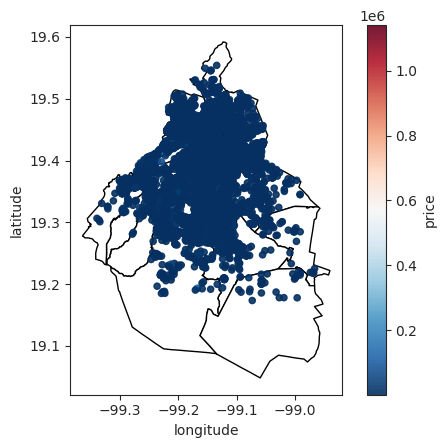

In [18]:
def plot_map_listings():

    from math import ceil
    import sys
    import geopandas as gpd
    import matplotlib.pyplot as plt
    import pandas as pd
    import numpy as np

    print(sys.version)
    print(pd.__name__, pd.__version__)
    print(gpd.__name__, gpd.__version__)
    print(np.__name__, np.__version__)
    print(plt.matplotlib.__name__, plt.matplotlib.__version__)

    cdmx = gpd.read_file('/content/drive/MyDrive/DataScience/data/mapa_mexico')\
        .query('CVE_EDO=="09"')\
        .set_index('CLAVE')

    base = cdmx.plot(color='white', edgecolor='black', scheme="naturalbreaks")

    # Convert to pandas DataFrame before plotting to avoid cudf.pandas plotting issues
    full_listings_pd = full_listings.to_pandas() if hasattr(full_listings, 'to_pandas') else full_listings

    above = full_listings_pd.plot(
        kind='scatter',
        x='longitude',
        y='latitude',
        alpha=0.9,
        ax=base,
        fig=(10,10),
        c="price",
        cmap=plt.get_cmap('RdBu_r'),
        colorbar=True)

    plt.show()

plot_map_listings()

## Availability Rate


We can calculate the corresponding Nights Intended to be Available, or Nights Available, for the 365-day look-back period as the sum of Nights Vacant and Nights Booked. We then divide it by 365, to obtain the corresponding Availability Rate.

$$\text{Availability Rate} = \frac{\text{Nights Vacant} + \text{Nights Boked} } { 365 }$$

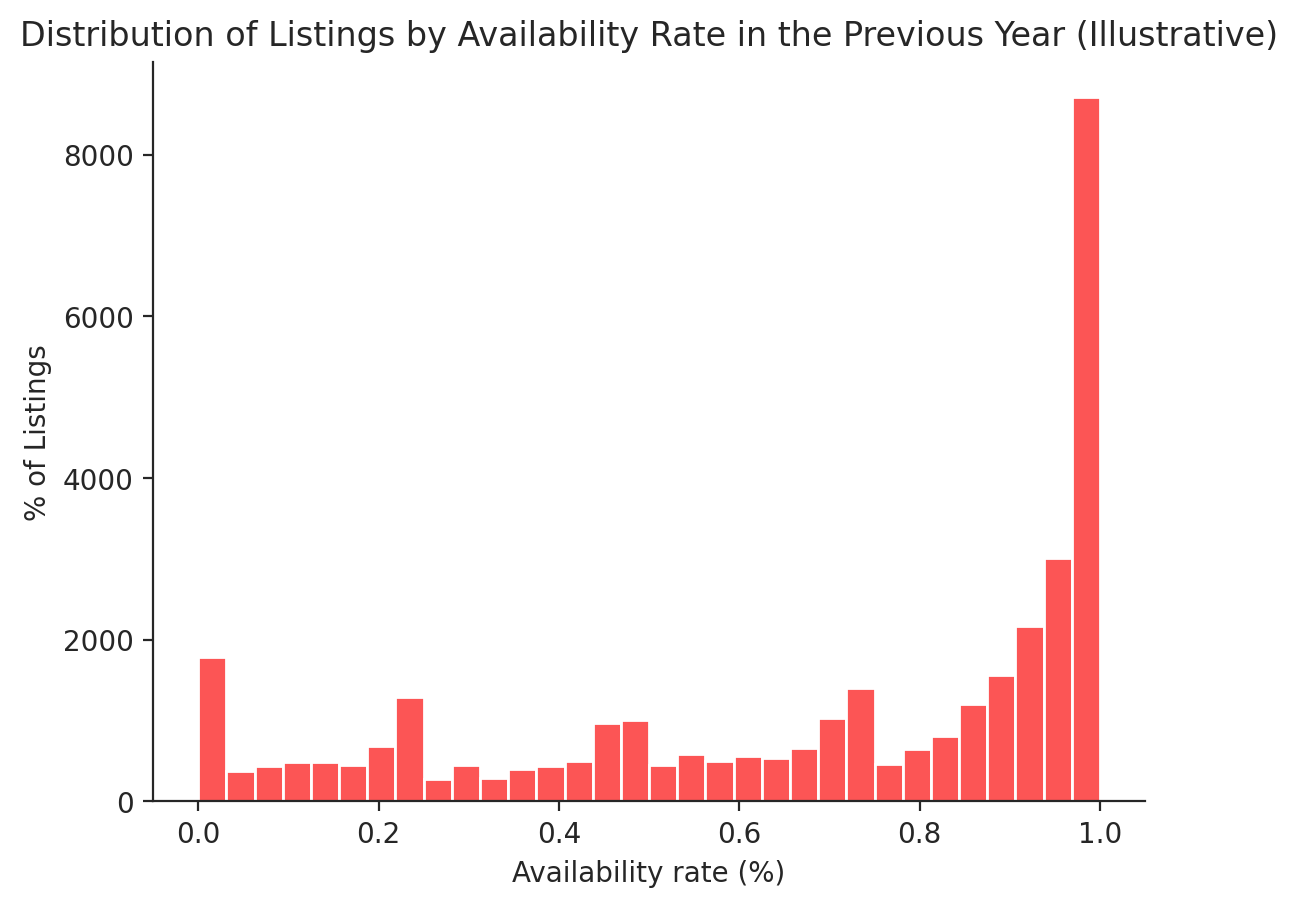

In [11]:
# We calculate the corresponding Nights Intended to be available.
full_listings['availability_rate'] = full_listings['availability_365'].map(lambda x: x/365)

# Plot the distribution
sns.histplot(full_listings['availability_rate'], color="#FC1C1C")
sns.despine()
plt.title("Distribution of Listings by Availability Rate in the Previous Year (Illustrative)")
plt.xlabel("Availability rate (%)")
plt.ylabel("% of Listings")
plt.show()

## Streakiness

We define a streak as a consecutive sequence of availability with a minimum of 2 consecutive nights, followed by a subsequent period of at least 2 consecutive nights of unavailability.

In [46]:
def join_calendar_data(calendar_dfs_with_dates, selected_columns_calendar):
    """
    Joins multiple calendar DataFrames into a single DataFrame, updating existing
    rows with newer non-null data and adding new rows.

    Parameters:
    - calendar_dfs_with_dates: A list of tuples, where each tuple contains
      (DataFrame, snapshot_date_string). The snapshot_date_string is used to sort
      the dataframes, effectively processing them from oldest to newest.
    - selected_columns_calendar: A list of columns to consider for the final DataFrame.
      'listing_id' and 'date' must be in selected_columns_calendar.

    Returns:
    - A single pandas DataFrame with all calendar data merged according to the rules.
    """
    required_keys = ['listing_id', 'date']
    if not all(col in selected_columns_calendar for col in required_keys):
        raise ValueError(f"The columns {required_keys} must be included in selected_columns_calendar.")

    # Sort the input dataframes by their snapshot dates (oldest to newest)
    sorted_calendars = sorted(
        calendar_dfs_with_dates,
        key=lambda x: pd.to_datetime(x[1])
    )

    # Initialize with expected columns and set multi-index for combine_first
    full_calendar_df = pd.DataFrame(columns=selected_columns_calendar)

    for df_calendar, _ in sorted_calendars:
        # Filter to selected columns
        current_df = df_calendar[selected_columns_calendar].copy()

        # Convert 'date' to datetime if not already
        if 'date' in current_df.columns:
            current_df['date'] = pd.to_datetime(current_df['date'])

        # Set 'listing_id' and 'date' as multi-index for combine_first operation
        current_df = current_df.set_index(required_keys)

        if full_calendar_df.empty:
            # For the first DataFrame, just use it as the base
            full_calendar_df = current_df
        else:
            # Ensure columns are aligned before combining, adding missing as NaN
            all_cols = list(set(full_calendar_df.columns).union(set(current_df.columns)))
            # Reindex both dataframes to have all_cols in the same order
            full_calendar_df = full_calendar_df.reindex(columns=all_cols)
            current_df = current_df.reindex(columns=all_cols)

            # Combine: current_df's non-null values overwrite full_calendar_df's values.
            # If current_df has NaN, full_calendar_df's value is kept.
            full_calendar_df = current_df.combine_first(full_calendar_df)

    return full_calendar_df.reset_index()

In [47]:
# Get the data
calendar_1 = read_url('https://data.insideairbnb.com/mexico/df/mexico-city/2026-06-15/data/calendar.csv.gz')
calendar_2 = read_url('https://data.insideairbnb.com/mexico/df/mexico-city/2026-03-30/data/calendar.csv.gz')
calendar_3 = read_url('https://data.insideairbnb.com/mexico/df/mexico-city/2025-12-29/data/calendar.csv.gz')

# Prepare the list of calendar DataFrames with their snapshot dates
# The dates are extracted from the URLs used to load the data.
calendar_data_sources = [
    (calendar_1, '2025-12-29'), # Dates based on the URL the data was read from
    (calendar_2, '2026-03-30'),
    (calendar_3, '2026-06-15'),
]

In [48]:
%%time
# Define selected columns for calendar data
selected_columns_calendar = ['listing_id', 'date', 'available']

# Call the function to join the calendar data
full_calendar = join_calendar_data(calendar_data_sources, selected_columns_calendar)

# Display the head of the resulting DataFrame and its shape
print("Shape of the full_calendar DataFrame:", full_calendar.shape)
display(full_calendar.head())

Shape of the full_calendar DataFrame: (16457373, 3)


,listing_id,date,available
0,35797,2025-12-31,f
1,35797,2026-01-01,f
2,35797,2026-01-02,t
3,35797,2026-01-03,t
4,35797,2026-01-04,t


CPU times: user 29 s, sys: 5.53 s, total: 34.5 s
Wall time: 35.4 s


In [49]:
# get random listing on listings DataFrame
list_sample = full_listings.sample()
# Find the data in calendar DataFrame
listing_selected = full_calendar[calendar['listing_id'] == int(list_sample['id'])]
listing_selected['available'] = listing_selected['available'].map(lambda x: x == 't')

# Time series plot: availability by date for listing_selected
listing_selected['date'] = pd.to_datetime(listing_selected['date'])
plt.figure(figsize=(12,4))
#plt.plot(listing_selected['date'], listing_selected['available'].astype(int), marker='o', linestyle='-', color="#FF5A5F")
plt.bar(listing_selected['date'], listing_selected['available'].astype(int), color="#FC1C1C", width=1, align='center')
plt.ylabel('Availability (1=Available, 0=Not available)')
plt.xlabel('Date')
plt.title(f"Availability Over Time for Listing ID {listing_selected['listing_id'].iloc[0]}")
plt.tight_layout()
plt.show()

NameError: name 'full_listings' is not defined

In [16]:
# Find streaks of availability and unavailability in listing_selectec
def find_streaks(df, min_streak=2):
    """
    Finds streaks of available and unavailable periods with at least min_streak consecutive days.
    Returns a list of tuples: (start_date, end_date, available, streak_length)
    """
    streaks = []
    current = None
    streak_start = None
    streak_len = 0

    for idx, row in df.iterrows():
        avail = row['available']
        date = row['date']
        if current is None:
            current = avail
            streak_start = date
            streak_len = 1
        elif avail == current:
            streak_len += 1
        else:
            if streak_len >= min_streak:
                streaks.append((streak_start, date - pd.Timedelta(days=1), current, streak_len))
            current = avail
            streak_start = date
            streak_len = 1
    # Add last streak
    if streak_len >= min_streak:
        streaks.append((streak_start, date, current, streak_len))
    return streaks


def get_streaks(calendar_listing: pd.DataFrame) -> int:
    """
    Compute and return number streaks
    """

    # Ensure sorted by date
    listing_selected = calendar_listing.sort_values('date').reset_index(drop=True)

    # Find all streaks
    all_streaks = find_streaks(listing_selected, min_streak=2)

    # Count and return streaks
    streaks_by_listing = pd.DataFrame(all_streaks, columns=['available_start', 'available_end', 'available', 'available_length'])

    return streaks_by_listing[streaks_by_listing['available'] == 't'].shape[0]


# add new column with value of streaks
full_listings['streaks'] = full_listings['id'].map(
    lambda id : get_streaks(full_calendar[full_calendar['listing_id'] == int(id)])
)

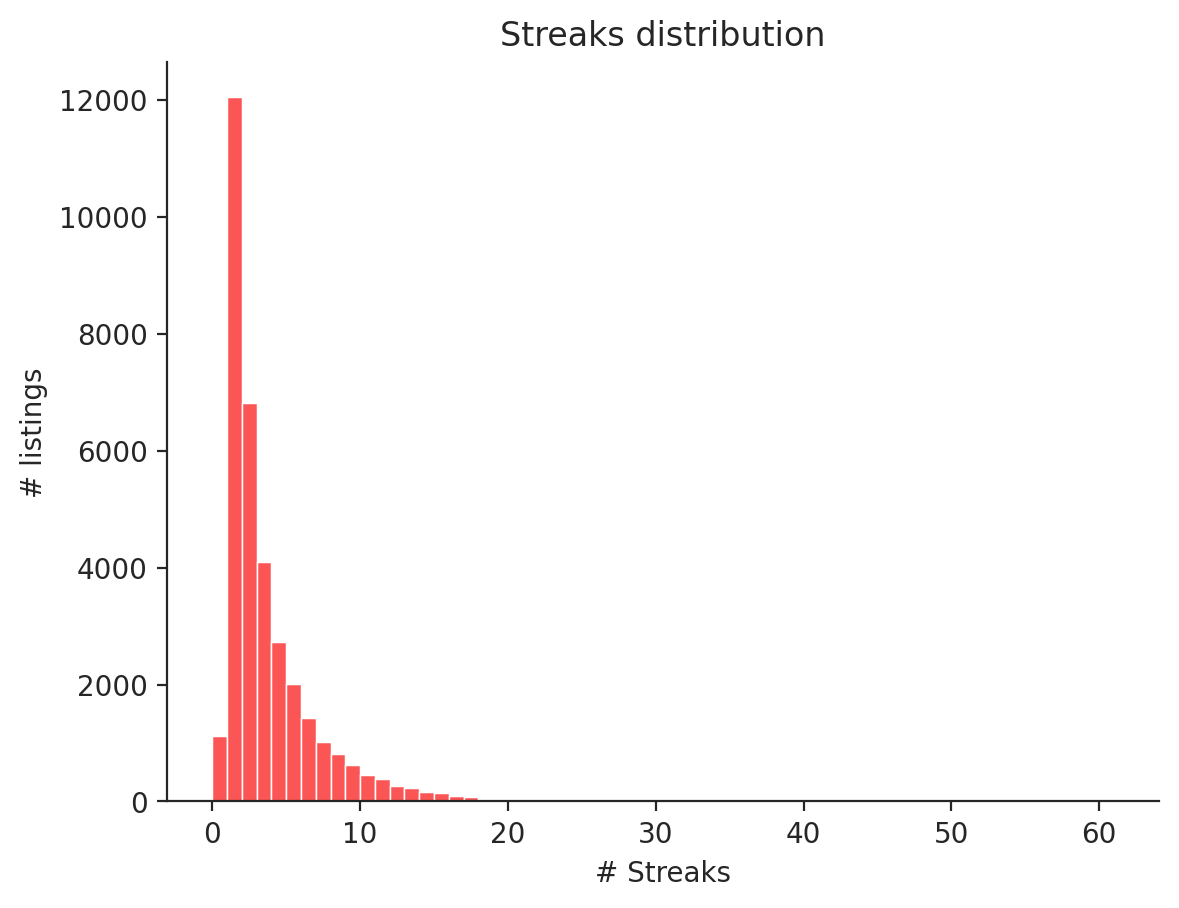

In [17]:
sns.histplot(full_listings['streaks'], color='#FC1C1C', binwidth=1)
sns.despine()
plt.title("Streaks distribution")
plt.xlabel("# Streaks")
plt.ylabel("# listings")
plt.show()

## Seasonality

In [18]:
def quarters_with_availability(calendar_listing: pd.DataFrame) -> int:
    """
    Returns the number of quarters (3-month periods) with at least one night available.
    """
    if calendar_listing.empty:
        return 0
    df = calendar_listing.copy()
    df['date'] = pd.to_datetime(df['date'])
    # Map 'available' to boolean if not already
    if df['available'].dtype != bool:
        df['available'] = df['available'].map(lambda x: x == 't')
    df['quarter'] = df['date'].dt.to_period('Q')
    quarters = df[df['available']].groupby('quarter').size()
    return len(quarters)

# Example: add as a feature to listings DataFrame
full_listings['quarters_with_availability'] = full_listings['id'].map(
    lambda id: quarters_with_availability(full_calendar[full_calendar['listing_id'] == int(id)])
)

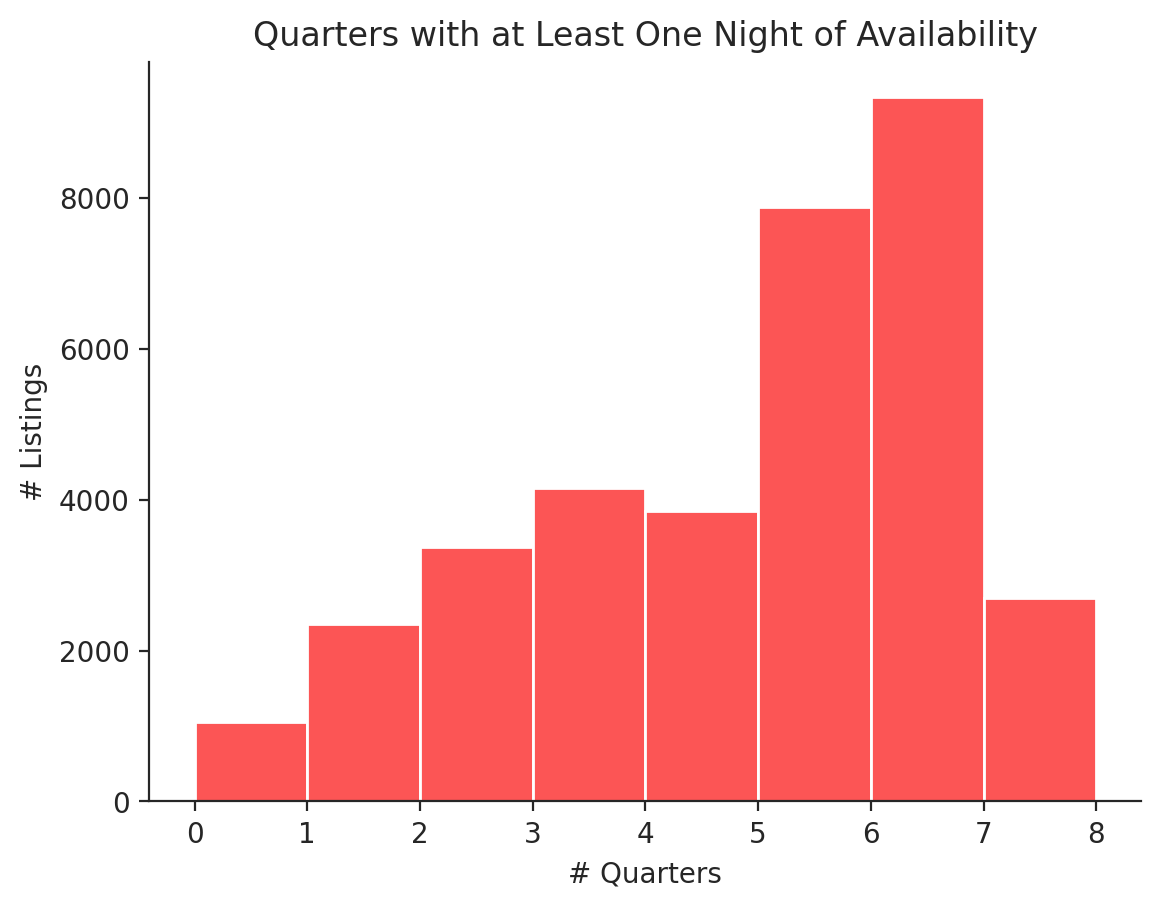

In [19]:
sns.histplot(full_listings['quarters_with_availability'], color='#FC1C1C', binwidth=1)
sns.despine()

plt.title("Quarters with at Least One Night of Availability")
plt.xlabel("# Quarters")
plt.ylabel("# Listings")
plt.show()

In [20]:
def max_consecutive_months_available(calendar_listing: pd.DataFrame) -> int:
    """
    Returns the maximum number of consecutive months with at least one night available.
    """
    if calendar_listing.empty:
        return 0
    df = calendar_listing.copy()
    df['date'] = pd.to_datetime(df['date'])
    # Map 'available' to boolean if not already
    if df['available'].dtype != bool:
        df['available'] = df['available'].map(lambda x: x == 't')
    # Get months with at least one available night
    months = df[df['available']].copy()
    if months.empty:
        return 0
    months['month'] = months['date'].dt.to_period('M')
    unique_months = sorted(months['month'].unique())
    # Find max consecutive months
    max_streak = streak = 1 if unique_months else 0
    for i in range(1, len(unique_months)):
        if unique_months[i-1] + 1 == unique_months[i]:
            streak += 1
            max_streak = max(max_streak, streak)
        else:
            streak = 1
    return max_streak

# Add as a feature to listings DataFrame
full_listings['max_consecutive_months_available'] = full_listings['id'].map(
    lambda id: max_consecutive_months_available(full_calendar[full_calendar['listing_id'] == int(id)])
)

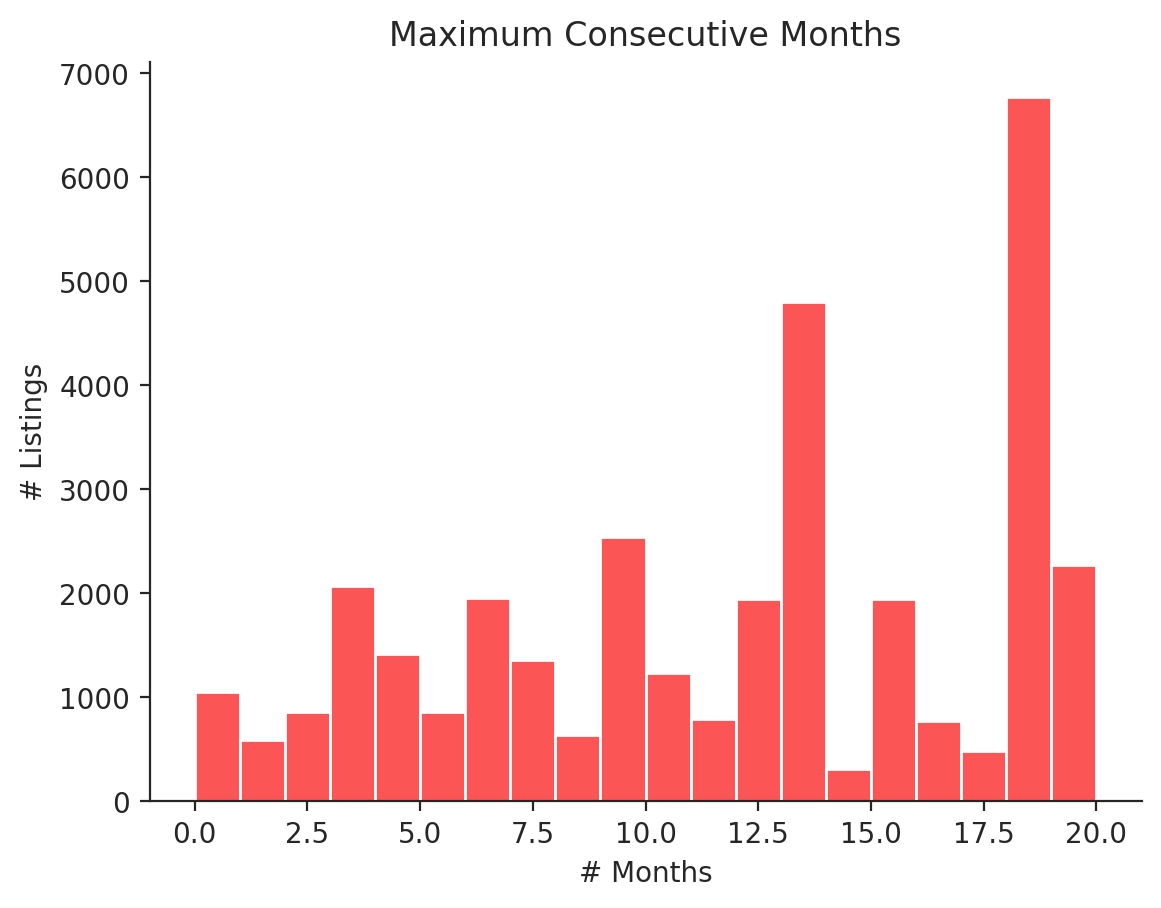

In [21]:
sns.histplot(full_listings['max_consecutive_months_available'], color='#FC1C1C', binwidth=1)
sns.despine()
plt.title("Maximum Consecutive Months")
plt.xlabel("# Months")
plt.ylabel("# Listings")
plt.show()

## Final Dataset

In [22]:
full_listings.head()

,id,longitude,price,neighbourhood_group_cleansed,availability_365,latitude,availability_rate,streaks,quarters_with_availability,max_consecutive_months_available
0,35797,-99.27,10020.00,NaN,363,19.38,0.99,1,6,18
1,44616,-99.18,21950.00,NaN,353,19.41,0.97,3,5,15
2,66055,-99.14,5259.00,NaN,180,19.31,0.49,1,3,7
3,67703,-99.17,3006.00,NaN,332,19.41,0.91,5,6,18
4,70644,-99.16,1636.33,NaN,197,19.35,0.54,4,5,7


In [23]:
full_listings.columns

Index(['id', 'longitude', 'price', 'neighbourhood_group_cleansed',
       'availability_365', 'latitude', 'availability_rate', 'streaks',
       'quarters_with_availability', 'max_consecutive_months_available'],
      dtype='object')

In [24]:
# Select features for clustering
features_selected = [
    'availability_rate',
    'streaks',
    'quarters_with_availability',
    'max_consecutive_months_available',
    ]

In [25]:
full_listings[features_selected].describe(percentiles=[0.01, .25, .5, .75, .99])

,availability_rate,streaks,quarters_with_availability,max_consecutive_months_available
count,34693.00,34693.00,34693.00,34693.00
mean,0.68,3.28,4.36,11.35
std,0.33,3.41,1.87,5.74
min,0.00,0.00,0.00,0.00
1%,0.00,0.00,0.00,0.00
25%,0.45,1.00,3.00,6.00
50%,0.82,2.00,5.00,13.00
75%,0.97,4.00,6.00,18.00
99%,1.00,16.00,7.00,19.00
max,1.00,61.00,8.00,20.00


In [27]:
# Save data as parquet into drive
full_listings.to_parquet('/content/drive/MyDrive/DataScience/airbnb_rapids.parquet', index=False)

In [50]:
# Save data as parquet into drive
full_calendar.to_parquet('/content/drive/MyDrive/DataScience/airbnb_calendar_rapids.parquet', index=False)

## Modeling

In [20]:
%load_ext cudf.pandas
%load_ext cuml.accel
%config InlineBackend.figure_format = 'retina'
%matplotlib inline

The cudf.pandas extension is already loaded. To reload it, use:
  %reload_ext cudf.pandas
The cuml.accel extension is already loaded. To reload it, use:
  %reload_ext cuml.accel


In [21]:
!nvidia-smi

Sat Aug  8 22:13:27 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   72C    P0             31W /   70W |     261MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [33]:
# Connect with Google Drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [34]:
import numpy as np
import pandas as pd
import cupy as cp

import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from time import time

# Parameters for synthetic data
n_clusters = 7
random_state = 42
n_init = 10
# Select features for clustering
features_selected = [
    'availability_rate',
    'streaks',
    'quarters_with_availability',
    'max_consecutive_months_available',
    ]

print("Gathering data...")
# Read data
data = pd.read_parquet('/content/drive/MyDrive/DataScience/airbnb_rapids.parquet')
print(f"Data shape: {data.shape}")

X = data[features_selected].values

# Convert the NumPy array to a CuPy array for GPU processing
X_gpu = cp.asarray(X)

print("Starting cuML K-Means...")
start_time = time()

# Initialize cuML's KMeans (note: cuML's KMeans does not use the 'n_init' parameter like scikit-learn)
kmeans = KMeans(n_clusters=n_clusters, random_state=random_state, n_init = n_init)
kmeans.fit(X_gpu)
end_time = time()

# Convert the cluster centers from a CuPy array back to a NumPy array for printing (if desired)
cluster_centers = cp.asnumpy(kmeans.cluster_centers_)
inertia = kmeans.inertia_

print(f"cuML K-Means completed in {end_time - start_time:.2f} seconds.")
print("Cluster centers:")
print(cluster_centers)
print(f"Inertia: {inertia}")

Gathering data...
Data shape: (34693, 10)
Starting cuML K-Means...
cuML K-Means completed in 0.37 seconds.
Cluster centers:
[[ 0.88613862  2.10003498  4.97458319 12.99207182]
 [ 0.59124863  8.60932056  4.1337108   8.95165505]
 [ 0.18840826  1.75567995  1.4007244   2.43513336]
 [ 0.83426105  8.30528455  5.92439024 17.40284553]
 [ 0.56720672  2.3822044   3.38562092  7.647653  ]
 [ 0.91965494  2.18082816  6.2915031  18.05483095]
 [ 0.70048998 17.65905632  5.52054795 15.60578387]]
Inertia: 197176.61383894528


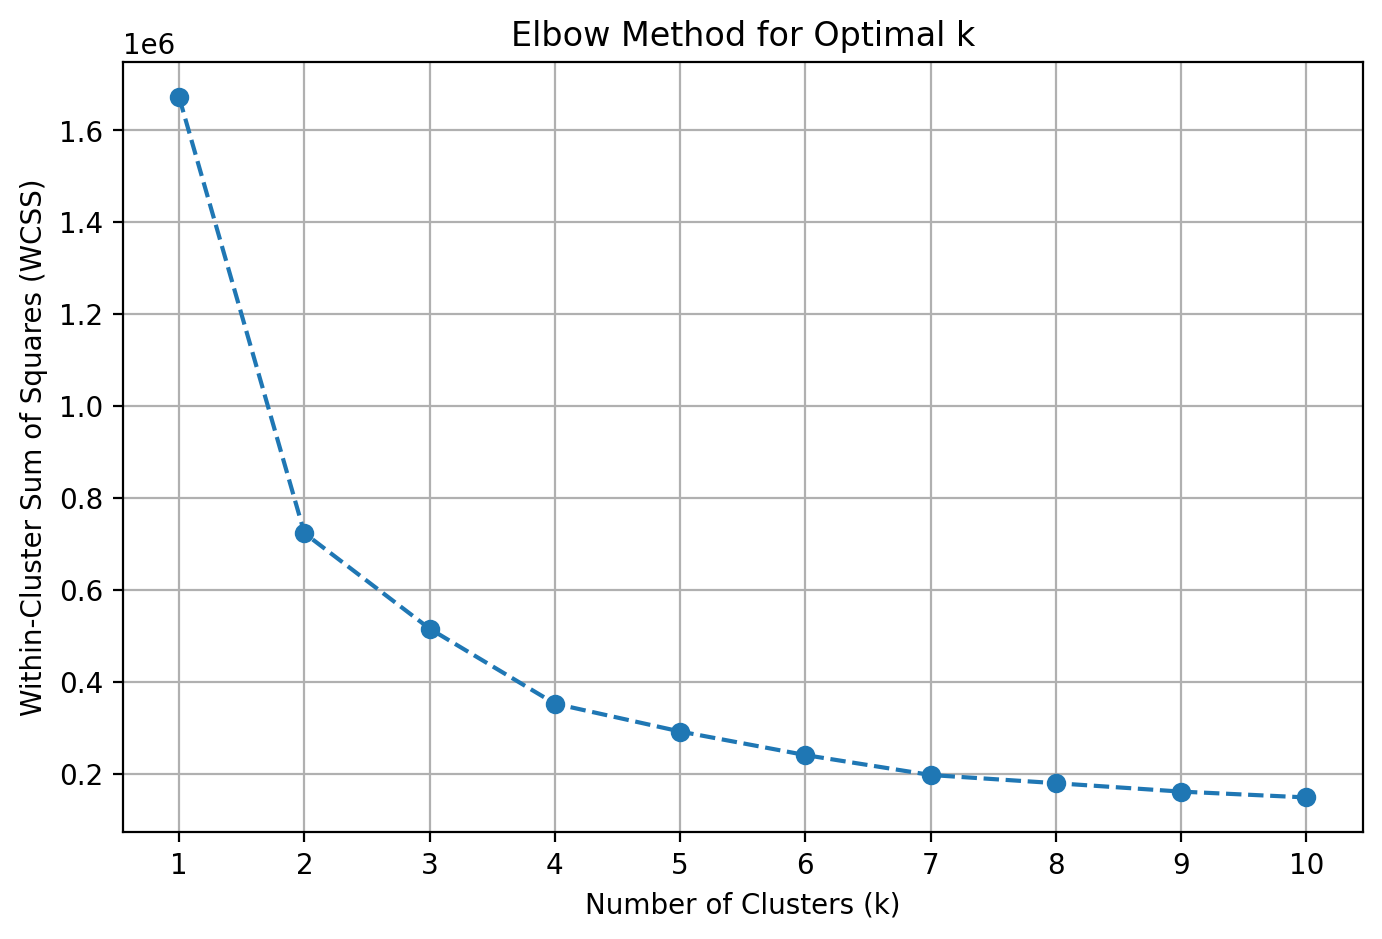

CPU times: user 2.01 s, sys: 40.8 ms, total: 2.05 s
Wall time: 2.05 s


In [35]:
%%time

# Define range of clusters to test
cluster_range = range(1, 11)
wcss = []

# Loop through different cluster numbers
for k in cluster_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10, max_iter=300)
    kmeans.fit(X_gpu)
    wcss.append(kmeans.inertia_)

# Plot WSSE vs. Number of Clusters
plt.figure(figsize=(8, 5))
plt.plot(cluster_range, wcss, marker='o', linestyle='--')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Within-Cluster Sum of Squares (WCSS)')
plt.title('Elbow Method for Optimal k')
plt.xticks(cluster_range)
plt.grid(True)
plt.show()

In [36]:
data['cluster'] = kmeans.predict(X)

In [37]:
data.describe()

,id,longitude,price,neighbourhood_group_cleansed,availability_365,latitude,availability_rate,streaks,quarters_with_availability,max_consecutive_months_available,cluster
count,3.469300e+04,34693.000000,3.127300e+04,0.0,34693.000000,34693.000000,34693.000000,34693.000000,34693.000000,34693.000000,34693.000000
mean,9.546984e+17,-99.163962,2.873465e+03,NaN,249.299686,19.403394,0.683013,3.278327,4.362350,11.353991,4.204623
std,6.359808e+17,0.032743,9.176312e+03,NaN,118.826344,0.044157,0.325552,3.414994,1.867559,5.738055,2.826920
min,3.579700e+04,-99.339630,1.876000e+01,NaN,0.000000,19.173447,0.000000,0.000000,0.000000,0.000000,0.000000
25%,5.364275e+07,-99.177520,1.061500e+03,NaN,165.000000,19.388866,0.452055,1.000000,3.000000,6.000000,1.000000
50%,1.122804e+18,-99.165950,1.735000e+03,NaN,298.000000,19.414660,0.816438,2.000000,5.000000,13.000000,5.000000
75%,1.532938e+18,-99.152260,2.833330e+03,NaN,354.000000,19.431700,0.969863,4.000000,6.000000,18.000000,7.000000
max,1.708364e+18,-98.966450,1.141520e+06,NaN,365.000000,19.553927,1.000000,61.000000,8.000000,20.000000,9.000000


/tmp/ipykernel_1902/2059854290.py:2: UserWarning: 
The palette list has fewer values (7) than needed (10) and will cycle, which may produce an uninterpretable plot.
  sns.histplot(data=data, x="availability_rate", hue="cluster", palette=sns.diverging_palette(220, 20, n=7))


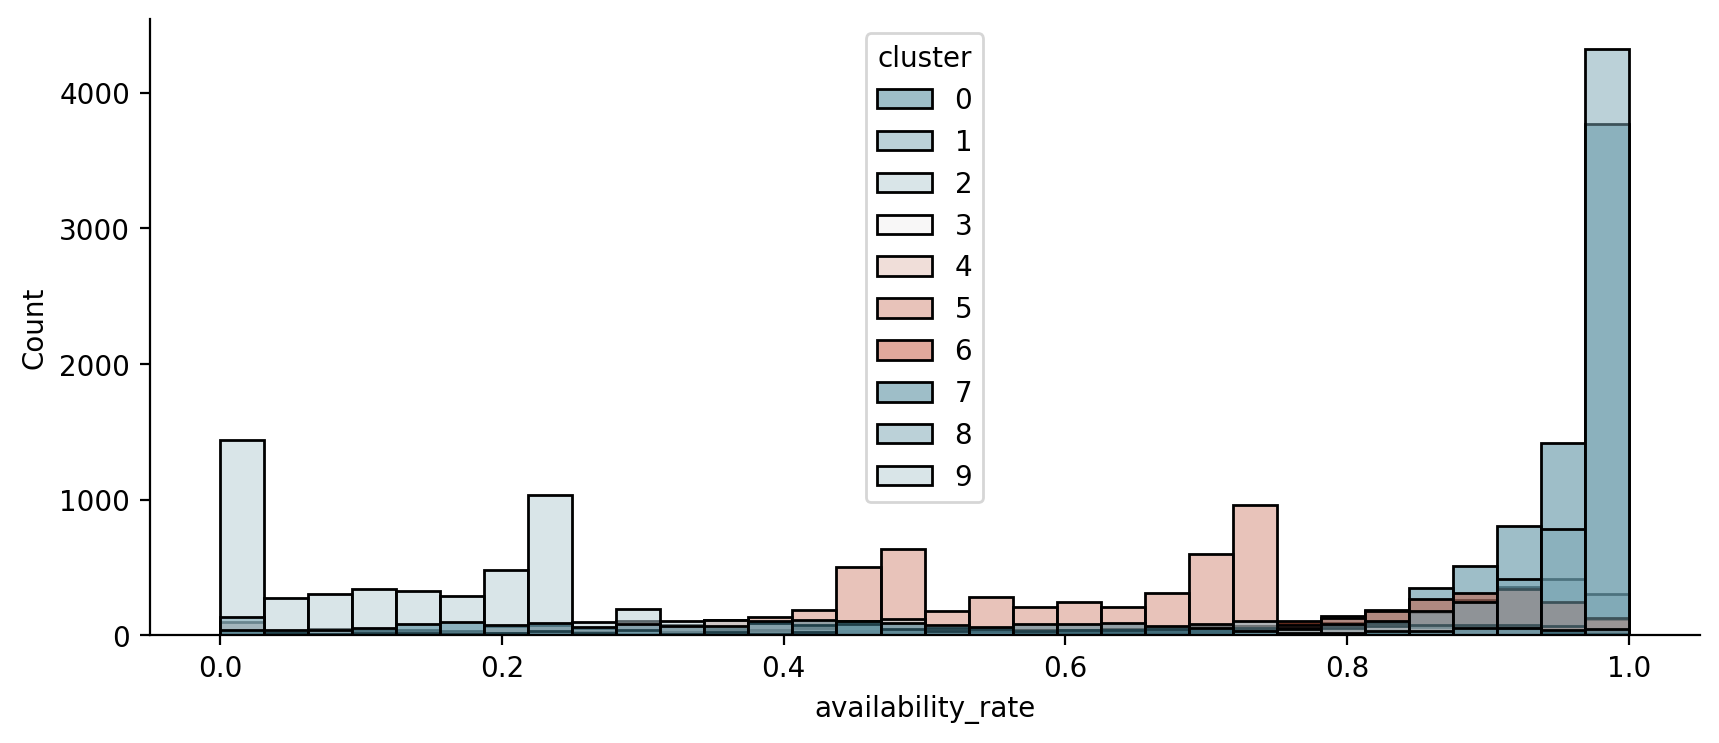

In [38]:
plt.figure(figsize=(10, 4))
sns.histplot(data=data, x="availability_rate", hue="cluster", palette=sns.diverging_palette(220, 20, n=7))
sns.despine()
plt.show()

/tmp/ipykernel_1902/794409989.py:2: UserWarning: 
The palette list has fewer values (7) than needed (10) and will cycle, which may produce an uninterpretable plot.
  sns.histplot(data=data, x="streaks", hue="cluster", binwidth=1, palette=sns.diverging_palette(220, 20, n=7))


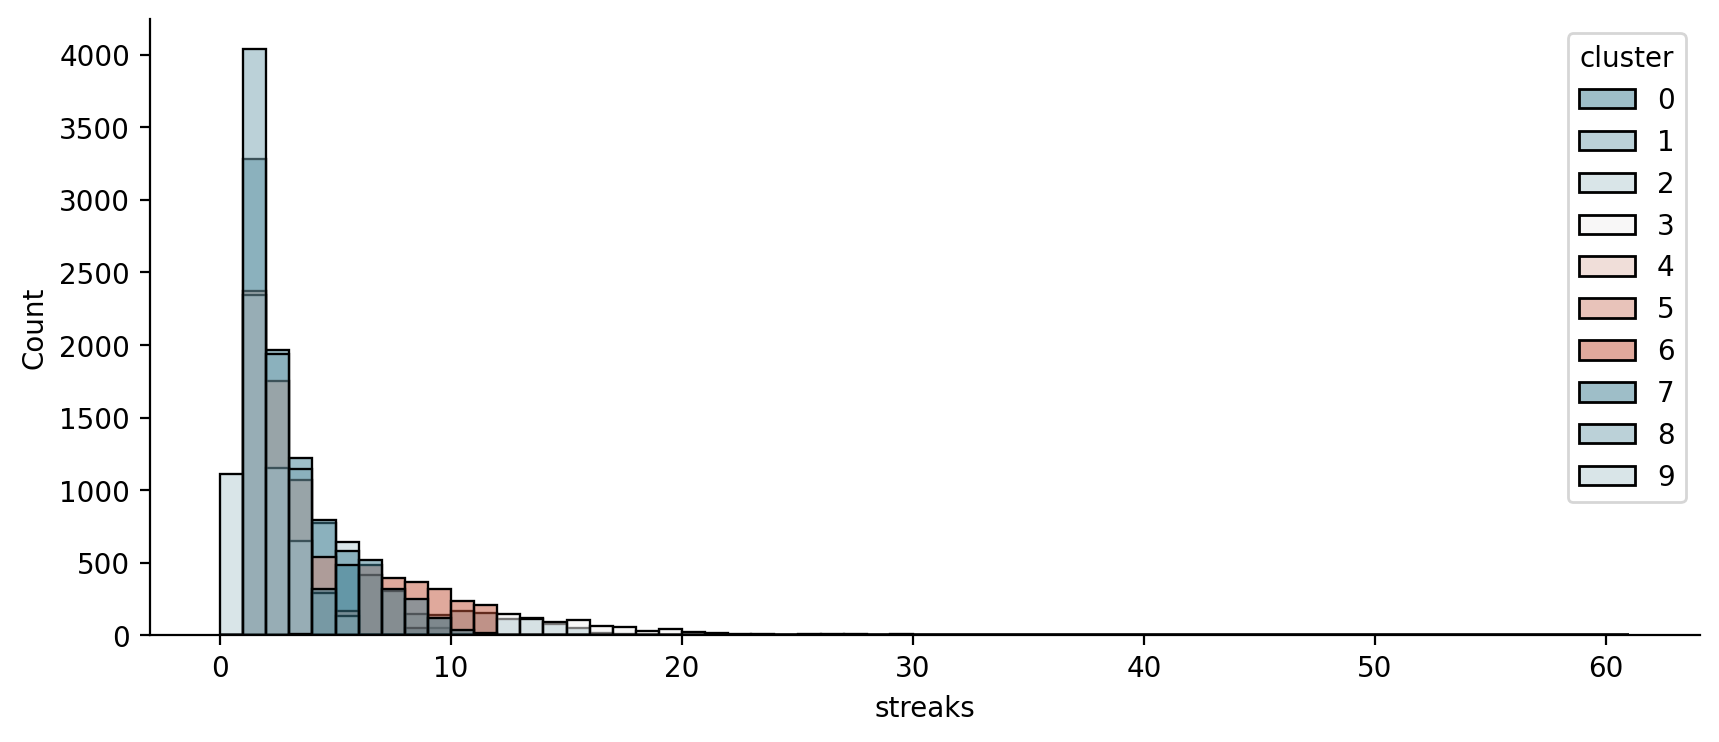

In [39]:
plt.figure(figsize=(10, 4))
sns.histplot(data=data, x="streaks", hue="cluster", binwidth=1, palette=sns.diverging_palette(220, 20, n=7))
sns.despine()
plt.show()

In [53]:
data.head()

,id,longitude,price,neighbourhood_group_cleansed,availability_365,latitude,availability_rate,streaks,quarters_with_availability,max_consecutive_months_available,cluster
0,35797,-99.27,10020.00,NaN,363,19.38,0.99,1,6,18,7
1,44616,-99.18,21950.00,NaN,353,19.41,0.97,3,5,15,1
2,66055,-99.14,5259.00,NaN,180,19.31,0.49,1,3,7,5
3,67703,-99.17,3006.00,NaN,332,19.41,0.91,5,6,18,7
4,70644,-99.16,1636.33,NaN,197,19.35,0.54,4,5,7,5


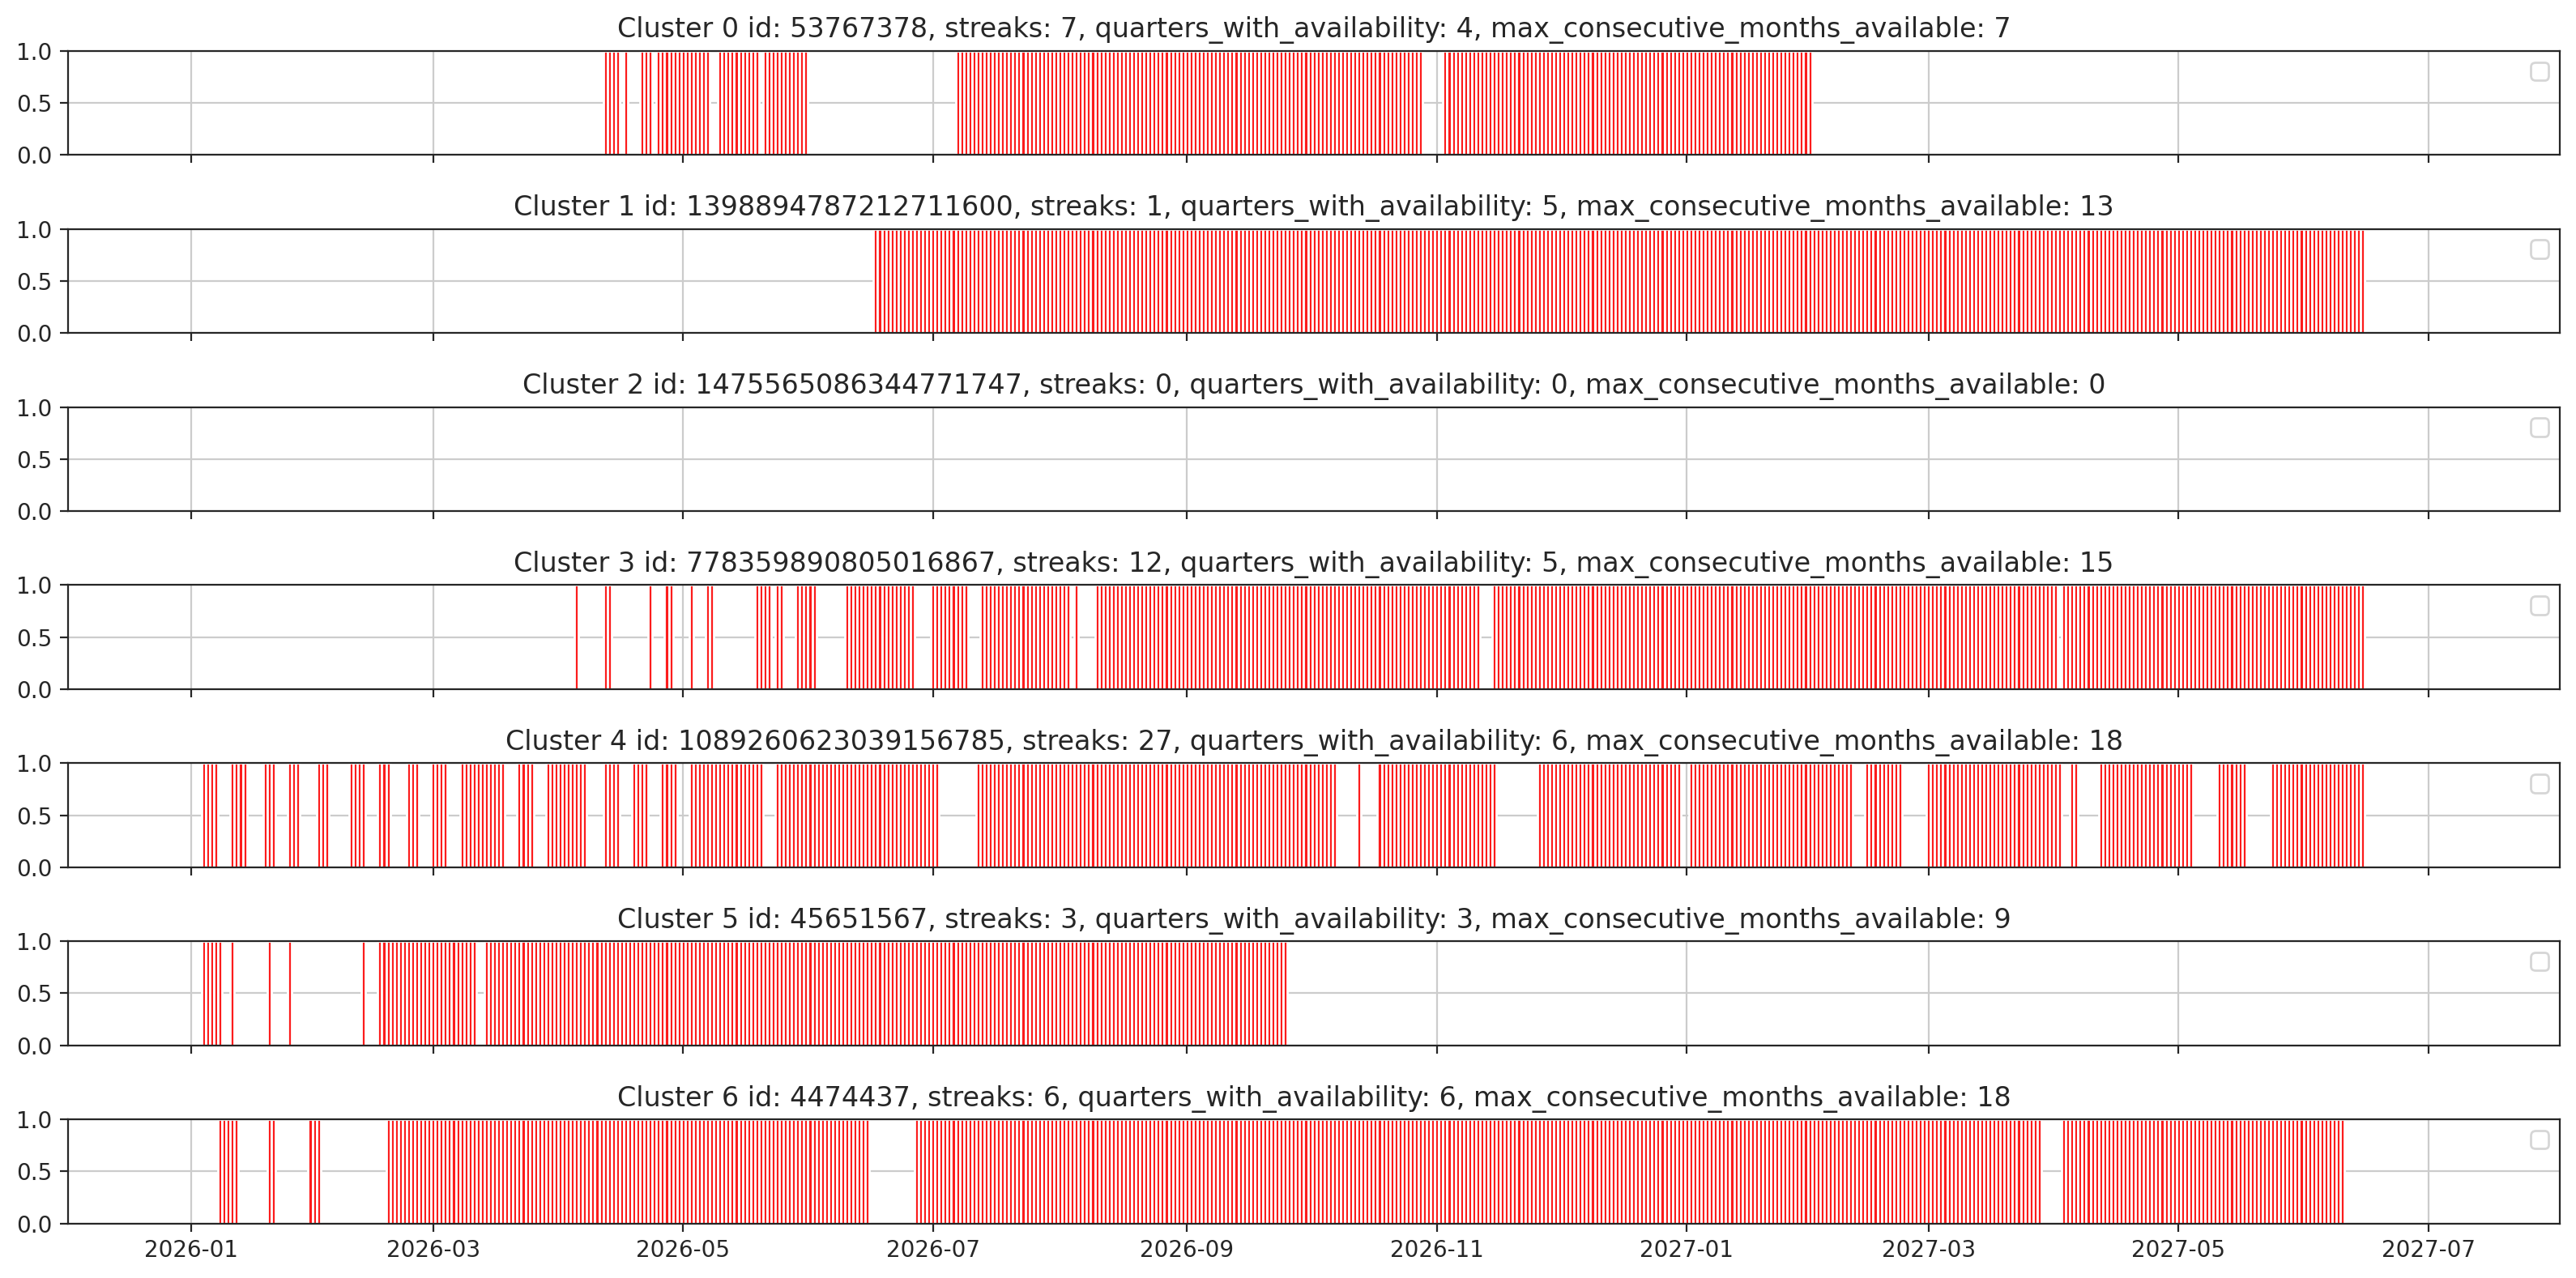

In [58]:
# select one row by cluster label and grap the time series of availability
df_sample = data.groupby('cluster').apply(lambda x: x.sample(1)).reset_index(drop=True)

fig, axes = plt.subplots(n_clusters, 1, figsize=(16, 8), sharex=True)

for i in range(n_clusters):
    # get id by cluster
    sample_streak = df_sample[df_sample['cluster'] == i]['streaks']
    sample_Q_w = df_sample[df_sample['cluster'] == i]['quarters_with_availability']
    sample_max_months = df_sample[df_sample['cluster'] == i]['max_consecutive_months_available']

    id_calendar = df_sample[df_sample['cluster'] == i]['id']
    aux_calendar = full_calendar[full_calendar['listing_id'] == int(id_calendar)]
    aux_calendar['available'] = aux_calendar['available'].map(lambda x: x == 't')

    # kind time serie
    # axes[i].plot(aux_calendar['date'], aux_calendar['available'].astype(int), marker='o', linestyle='-', color="#FF5A5F")

    # 'Availability (1=Available, 0=Not available)'
    axes[i].bar(aux_calendar['date'], aux_calendar['available'].astype(int), color="#FC1C1C", width=1.0, align='center')
    axes[i].set_title(f'Cluster {i} id: {int(id_calendar)}, streaks: {int(sample_streak)}, quarters_with_availability: {int(sample_Q_w)}, max_consecutive_months_available: {int(sample_max_months)}')
    axes[i].legend()
    axes[i].grid(True)
    axes[i].set_ylim([0, 1])

plt.tight_layout()  # Ajusta el espaciado entre subgráficos
plt.show()